[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/firefly1248/demo-notebooks/blob/main/notebooks/gbdt/gbdt_defaults.ipynb)

# Gradient boosting defaults: what XGBoost, LightGBM and CatBoost actually run with

Called with no arguments, XGBoost and LightGBM build 100 trees at a fixed learning rate of 0.3 and
0.1, and CatBoost builds 1000 trees at a learning rate it computes from the number of rows and
iterations: on 500 rows with 1000 iterations it picks 0.008, and on 200 000 rows 0.099. That
computed rate also changes when an `eval_set` is passed, so a "diagnostic" run with a validation set
is not the default model. All three libraries adapt something to the data: XGBoost and LightGBM
start from the class prior, and XGBoost's `min_child_weight=1` becomes a minimum leaf of about
`1 / (p (1 - p))` rows on the first tree. On CPU CatBoost always boosts in `Plain` mode; the
switch to `Ordered` below 50 000 rows is a GPU rule.

Each section checks one claim about the defaults against the installed versions and quotes the
documentation of those versions. The data is `phoneme` (5404 rows, numeric), `adult` (48 842 rows,
8 categorical columns) and synthetic sets with fixed seeds.

About three minutes on a laptop CPU, also when limited to two cores; most of it is the timing of
`Ordered` against `Plain` in section 8. A free Colab CPU is slower, and installing the pinned
libraries adds a minute.

In [1]:
import importlib.metadata as md
import os
import platform

PINS = {"xgboost": "3.4.1", "lightgbm": "4.7.0", "catboost": "1.2.10"}


def installed(package):
    try:
        return md.version(package)
    except md.PackageNotFoundError:
        return None


missing = [f"{p}=={v}" for p, v in PINS.items() if installed(p) != v]
if missing:
    %pip install -q {" ".join(missing)}
# Written with Python 3.12, numpy 2.5.4, pandas 3.1.0, scikit-learn 1.9.1 and scipy 1.18.1.
# The cores this process may use; os.cpu_count() counts the whole machine.
THREADS = len(os.sched_getaffinity(0)) if hasattr(os, "sched_getaffinity") else os.cpu_count()
print("Python", platform.python_version(), "| CPU threads:", THREADS)
print({p: installed(p) for p in (*PINS, "numpy", "pandas", "scikit-learn", "scipy")})

Python 3.12.12 | CPU threads: 14
{'xgboost': '3.4.1', 'lightgbm': '4.7.0', 'catboost': '1.2.10', 'numpy': '2.5.4', 'pandas': '3.1.0', 'scikit-learn': '1.9.1', 'scipy': '1.18.1'}


In [2]:
import inspect
import io
import json
import time
import urllib.request
import warnings
from functools import partial

import catboost
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from catboost import CatBoost, CatBoostClassifier, CatBoostError, CatBoostRegressor, Pool
from catboost.utils import get_gpu_device_count
from scipy.io import arff
from sklearn.datasets import fetch_openml, make_classification, make_regression
from sklearn.metrics import log_loss
from sklearn.model_selection import train_test_split

# LightGBM names the columns of a NumPy array itself and then warns that they are missing.
warnings.filterwarnings("ignore", message="X does not have valid feature names")

SEED = 0
SEEDS = range(5)
QUIET = dict(verbose=0, allow_writing_files=False)
BENCHMARK = "https://raw.githubusercontent.com/firefly1248/SmallDataBenchmarks/0267ce719ed916b682bb0c5a6fe17c0a25de6bd9/"

plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"]
BLUE, GREY, INK = "#2C5F8A", "#8a8a8a", "#1a1a1a"


class StopAfterFirst:
    """CatBoost fixes its automatic parameters before the first tree; stop right after it."""

    def after_iteration(self, info):
        return False  # False stops training


def first_tree_params(model, X, y=None, **fit_kw):
    """All parameters CatBoost resolved for this data, from a fit that builds one tree."""
    model.fit(X, y, callbacks=[StopAfterFirst()], **fit_kw)
    return model.get_all_params()


# Each library's classifier with default parameters, only its console output turned off.
DEFAULT = {"XGBoost": xgb.XGBClassifier, "LightGBM": partial(lgb.LGBMClassifier, verbose=-1),
           "CatBoost": partial(CatBoostClassifier, **QUIET)}


def xgb_config(model):
    """XGBoost's saved training configuration."""
    return json.loads(model.get_booster().save_config())["learner"]


def n_trees(model):
    if isinstance(model, xgb.XGBModel):
        return model.get_booster().num_boosted_rounds()
    return model.booster_.num_trees() if isinstance(model, lgb.LGBMModel) else model.tree_count_


def load_phoneme():
    with urllib.request.urlopen(BENCHMARK + "datasets/phoneme.arff") as response:
        df = pd.DataFrame(arff.loadarff(io.StringIO(response.read().decode()))[0])
    target = df.pop("Class").str.decode("utf-8")
    return df.astype(float).to_numpy(), (target == sorted(target.unique())[1]).astype(int).to_numpy()


X_ph, y_ph = load_phoneme()
adult = fetch_openml("adult", version=2, as_frame=True)
X_ad, y_ad = adult.data, (adult.target == ">50K").astype(int).to_numpy()
CATS = list(X_ad.select_dtypes("category").columns)
print(f"phoneme: {X_ph.shape}, positive share {y_ph.mean():.3f}")
print(f"adult: {X_ad.shape}, positive share {y_ad.mean():.3f}, categorical columns {len(CATS)}")

phoneme: (5404, 5), positive share 0.293
adult: (48842, 14), positive share 0.239, categorical columns 8


## 0. What an unfitted model reports, and what the fitted one used

A common way to look at defaults is to read `learning_rate`, `n_estimators` and the like from an
unfitted estimator. The cell prints those attributes and how many entries of `get_params()` are
`None`.

In [3]:
ATTRS = ["learning_rate", "n_estimators", "max_depth", "subsample", "reg_lambda", "enable_categorical", "tree_method"]
unfitted = {"XGBClassifier": xgb.XGBClassifier(), "LGBMClassifier": lgb.LGBMClassifier(),
            "CatBoostClassifier": CatBoostClassifier()}
print(pd.DataFrame({name: {a: repr(getattr(m, a, "no attribute")) for a in ATTRS}
                    for name, m in unfitted.items()}).to_string())
print()
for name, m in unfitted.items():
    params = m.get_params()
    print(f"{name}.get_params(): {len(params)} entries, {sum(v is None for v in params.values())} of them None")

                   XGBClassifier  LGBMClassifier CatBoostClassifier
learning_rate               None             0.1     'no attribute'
n_estimators                None             100     'no attribute'
max_depth                   None              -1     'no attribute'
subsample                   None             1.0     'no attribute'
reg_lambda                  None             0.0     'no attribute'
enable_categorical          True  'no attribute'     'no attribute'
tree_method                 None  'no attribute'     'no attribute'

XGBClassifier.get_params(): 40 entries, 37 of them None
LGBMClassifier.get_params(): 19 entries, 4 of them None
CatBoostClassifier.get_params(): 0 entries, 0 of them None


Unfitted `XGBClassifier` stores `None` for every hyperparameter except `objective`, `missing` and
`enable_categorical`, and leaves the value to the C++ core. `CatBoostClassifier().get_params()` is an
empty dict: it returns only what was passed. Only LightGBM's sklearn class keeps its defaults on the
object. So reading an unfitted XGBoost model gives `None` for the learning rate, the number of trees
and the depth, and `CatBoostClassifier().get_params().get("depth", 6)` returns whatever fallback the
caller typed, not anything read from CatBoost.

`effective_defaults` reads what the booster used after a fit: XGBoost's saved config, LightGBM's
parameter block in `model_to_string()`, and CatBoost's `get_all_params()`.

In [4]:
def lgb_model_params(model):
    """The `[name: value]` parameter block LightGBM writes into the model string."""
    text = model.booster_.model_to_string()
    block = text[text.index("parameters:"):text.index("end of parameters")]
    return dict(line[1:-1].split(": ", 1) for line in block.splitlines()[1:] if line.startswith("["))


def effective_defaults(model):
    """The values one fitted classifier used, under one name per concept."""
    if isinstance(model, xgb.XGBModel):
        cfg = xgb_config(model)
        tree, gbtree = cfg["gradient_booster"]["tree_train_param"], cfg["gradient_booster"]["gbtree_train_param"]
        return {"trees": n_trees(model), "learning rate": float(tree["eta"]),
                "growth": tree["grow_policy"], "max depth": tree["max_depth"], "max leaves": tree["max_leaves"],
                "min leaf": f"min_child_weight={tree['min_child_weight']}", "L2": tree["lambda"], "L1": tree["alpha"],
                "min split gain": tree["gamma"], "split noise": "none",
                "row sampling": f"subsample={tree['subsample']}", "column sampling": tree["colsample_bytree"],
                "bins": tree["max_bin"], "split finding": f"tree_method={gbtree['tree_method']}, updater={gbtree['updater']}",
                "boosting": cfg["learner_train_param"]["booster"],
                "start": f"base_score={cfg['learner_model_param']['base_score']}"}
    if isinstance(model, lgb.LGBMModel):
        p = lgb_model_params(model)
        return {"trees": n_trees(model), "learning rate": float(p["learning_rate"]),
                "growth": "leaf-wise", "max depth": p["max_depth"], "max leaves": p["num_leaves"],
                "min leaf": f"min_data_in_leaf={p['min_data_in_leaf']}, min_sum_hessian_in_leaf={p['min_sum_hessian_in_leaf']}",
                "L2": p["lambda_l2"], "L1": p["lambda_l1"], "min split gain": p["min_gain_to_split"], "split noise": "none",
                "row sampling": f"bagging_fraction={p['bagging_fraction']}, bagging_freq={p['bagging_freq']}",
                "column sampling": p["feature_fraction"], "bins": p["max_bin"], "split finding": "histogram",
                "boosting": p["boosting"], "start": f"boost_from_average={p['boost_from_average']}"}
    p = model.get_all_params()
    return {"trees": n_trees(model), "learning rate": round(p["learning_rate"], 6),
            "growth": p["grow_policy"], "max depth": p["depth"], "max leaves": 2 ** p["depth"],
            "min leaf": f"min_data_in_leaf={p['min_data_in_leaf']}", "L2": p["l2_leaf_reg"], "L1": "none",
            "min split gain": "none", "split noise": f"random_strength={p['random_strength']}",
            "row sampling": f"{p['bootstrap_type']}, subsample={p.get('subsample', 1):.2g}",
            "column sampling": p["rsm"], "bins": p["border_count"], "split finding": p["feature_border_type"] + " borders",
            "boosting": p["boosting_type"], "start": f"boost_from_average={p['boost_from_average']}"}


X_small, y_small = make_classification(2000, 10, n_informative=5, n_redundant=0, random_state=SEED)
fitted = {name: make().fit(X_small, y_small) for name, make in DEFAULT.items()}
DEFAULTS = pd.DataFrame({name: effective_defaults(m) for name, m in fitted.items()})
print("2000 rows, 10 features, binary")
print(DEFAULTS.to_string())

2000 rows, 10 features, binary
                                                           XGBoost                                            LightGBM                  CatBoost
trees                                                          100                                                 100                      1000
learning rate                                                  0.3                                                 0.1                  0.013851
growth                                                   depthwise                                           leaf-wise             SymmetricTree
max depth                                                        6                                                  -1                         6
max leaves                                                       0                                                  31                        64
min leaf                                        min_child_weight=1  min_data_in_leaf=20, min_sum_he

This is the table the rest of the notebook checks. CatBoost's learning rate in it belongs to this
data: 2000 rows and 1000 iterations (section 2). XGBoost's config keeps `tree_method=auto`, and the
updater it resolves to is the histogram one (section 1).

## 1. Number of trees, the native APIs, and `tree_method`

The sklearn wrappers' tree counts are read from fitted models. The native training functions'
defaults come from their signatures. Then a model with `tree_method="auto"` is compared with one
with `tree_method="hist"`.

In [5]:
print("trees after a default fit:", DEFAULTS.loc["trees"].to_dict())
print("xgb.train   ", inspect.signature(xgb.train).parameters["num_boost_round"])
print("lgb.train   ", inspect.signature(lgb.train).parameters["num_boost_round"])
print("catboost.train", inspect.signature(catboost.train).parameters["num_boost_round"])

auto = xgb.XGBClassifier(tree_method="auto").fit(X_small, y_small)
hist = xgb.XGBClassifier(tree_method="hist").fit(X_small, y_small)
print("tree_method auto and hist give the same predictions:",
      np.array_equal(auto.predict_proba(X_small), hist.predict_proba(X_small)))

trees after a default fit: {'XGBoost': 100, 'LightGBM': 100, 'CatBoost': 1000}
xgb.train    num_boost_round: int = 10
lgb.train    num_boost_round: int = 100
catboost.train num_boost_round=None


tree_method auto and hist give the same predictions: True


XGBoost's native API does have a default: `xgb.train` builds 10 rounds. LightGBM's
`lgb.train` builds 100, the same as its sklearn class, and CatBoost's `train` takes `None` and falls
back to its 1000 iterations.

XGBoost did not replace `auto` with `hist`; it redefined `auto`. The config still says
`tree_method=auto`, and `auto` builds the same trees as `hist`. From the
[3.4.1 parameter docs](https://github.com/dmlc/xgboost/blob/v3.4.1/doc/parameter.rst):
"`auto`: Same as the `hist` tree method." From the
[2.0.0 release notes](https://github.com/dmlc/xgboost/blob/v3.4.1/NEWS.md#200-2023-aug-16):
"Starting from 2.0, the `hist` tree method will be the default. In previous versions, XGBoost
chooses `approx` or `exact` depending on the input data and training environment."

## 2. CatBoost's automatic learning rate

CatBoost sets the rate before the first tree, so each point of the grid is read from a fit that
stops after one tree. `Logloss`, 20 features, all of them informative or noise, none redundant.

In [6]:
X_lr, y_lr = make_classification(200_000, 20, n_informative=10, n_redundant=0, random_state=SEED)


def lr_at(n=10_000, iterations=1000, X=X_lr, y=y_lr, model=CatBoostClassifier, eval_set=None, **params):
    """The learning rate CatBoost picks for the first n rows."""
    model = model(iterations=iterations, **QUIET, **params)
    return round(first_tree_params(model, X[:n], y[:n], eval_set=eval_set)["learning_rate"], 6)


ROWS, ITERATIONS = (500, 2_000, 10_000, 50_000, 200_000), (100, 300, 1_000, 3_000)
LR = pd.DataFrame({it: [lr_at(n, it) for n in ROWS] for it in ITERATIONS}, index=pd.Index(ROWS, name="rows"))
LR.columns.name = "iterations"
print(LR.round(4).to_string())

quick = CatBoostClassifier(iterations=1000, **QUIET)
lr_quick = first_tree_params(quick, X_lr[:2000], y_lr[:2000])["learning_rate"]
full = CatBoostClassifier(iterations=1000, **QUIET).fit(X_lr[:2000], y_lr[:2000])
print(f"check at 2000 rows, 1000 iterations: one tree {lr_quick:.6f} ({quick.tree_count_} tree), "
      f"full fit {full.get_all_params()['learning_rate']:.6f} ({full.tree_count_} trees)")

iterations    100     300     1000    3000
rows                                      
500         0.0633  0.0231  0.0077  0.0028
2000        0.1144  0.0418  0.0139  0.0051
10000       0.2275  0.0831  0.0275  0.0101
50000       0.4523  0.1651  0.0548  0.0200
200000      0.5000  0.2985  0.0990  0.0361


check at 2000 rows, 1000 iterations: one tree 0.013851 (1 tree), full fit 0.013851 (1000 trees)


The rate grows with the number of rows and falls with the number of iterations. At the default 1000
iterations it reaches 0.05 only from about 50 000 rows; on a few thousand
rows it is below 0.03. The rate read after one tree equals the rate of the full fit.

Does it depend on anything else? The next cell varies the number of features, the class balance and
the depth at 10 000 rows, looks for a ceiling, and passes an `eval_set`.

In [7]:
rows = {}
for p in (5, 20, 100):
    X_p, y_p = make_classification(10_000, p, n_informative=min(p, 5), n_redundant=0, random_state=SEED)
    rows[f"{p} features"] = lr_at(X=X_p, y=y_p)
rows["5% positive"] = lr_at(y=(np.random.default_rng(SEED).random(len(y_lr)) < 0.05).astype(int))
rows["depth 8"] = lr_at(depth=8)
for it in (10, 30):
    rows[f"200 000 rows, {it} iterations"] = lr_at(n=200_000, iterations=it)
held_out = (X_lr[-2000:], y_lr[-2000:])
rows["8000 rows"] = lr_at(n=8000)
rows["8000 rows, eval_set of 2000"] = lr_at(n=8000, eval_set=held_out)
rows["8000 rows, eval_set of 200"] = lr_at(n=8000, eval_set=(X_lr[-200:], y_lr[-200:]))
rows["8000 rows, eval_set, use_best_model=False"] = lr_at(n=8000, eval_set=held_out, use_best_model=False)
rows["8000 rows, 100 iterations"] = lr_at(n=8000, iterations=100)
rows["8000 rows, 100 iterations, eval_set"] = lr_at(n=8000, iterations=100, eval_set=held_out)
print(pd.Series(rows, name="learning rate").to_string())

5 features                                   0.027538
20 features                                  0.027538
100 features                                 0.027538
5% positive                                  0.027538
depth 8                                      0.027538
200 000 rows, 10 iterations                  0.500000
200 000 rows, 30 iterations                  0.500000
8000 rows                                    0.025035
8000 rows, eval_set of 2000                  0.052963
8000 rows, eval_set of 200                   0.052963
8000 rows, eval_set, use_best_model=False    0.025035
8000 rows, 100 iterations                    0.206801
8000 rows, 100 iterations, eval_set          0.144202


At a fixed number of rows and iterations the rate does not depend on the number of features, the
class balance or the depth, and it stops at 0.5. The `eval_set` does change it: with an `eval_set`
and `use_best_model` on (its default once an `eval_set` is given), CatBoost uses another formula. At
8000 rows and 1000 iterations the rate goes from 0.025 to 0.053; at 100 iterations it goes down, from
0.207 to 0.144. The size of the `eval_set` does not matter, and with `use_best_model=False` the rate
is the one without an `eval_set`. A diagnostic run with an `eval_set` therefore trains at a different
rate than the default model it is meant to diagnose.

Which losses get an automatic rate, and what turns it off? Each of the three parameters is set
alone, to the value CatBoost would use anyway for `Logloss` (`l2_leaf_reg=3`,
`leaf_estimation_iterations=10`, `leaf_estimation_method="Newton"`).

In [8]:
X_reg, y_reg = make_regression(10_000, 20, noise=10, random_state=SEED)
y_3 = np.digitize(X_reg[:, 0], [-0.5, 0.5])
AUTO_OFF = ("l2_leaf_reg", "leaf_estimation_iterations", "leaf_estimation_method")
logloss = first_tree_params(CatBoostClassifier(iterations=1000, **QUIET), X_lr[:10_000], y_lr[:10_000])
losses = {"Logloss": round(logloss["learning_rate"], 6), "CrossEntropy": lr_at(loss_function="CrossEntropy"),
          "MultiClass": lr_at(X=X_reg, y=y_3, loss_function="MultiClass"),
          "RMSE": lr_at(X=X_reg, y=y_reg, model=CatBoostRegressor),
          "MAE": lr_at(X=X_reg, y=y_reg, model=CatBoostRegressor, loss_function="MAE"),
          "Quantile": lr_at(X=X_reg, y=y_reg, model=CatBoostRegressor, loss_function="Quantile:alpha=0.9")}
print("10 000 rows, 1000 iterations")
print(pd.Series(losses, name="learning rate").to_string())

print("\nLogloss resolves to", {k: logloss[k] for k in AUTO_OFF})
explicit = {k: lr_at(**{k: logloss[k]}) for k in AUTO_OFF}
explicit |= {"depth": lr_at(depth=6), "random_strength": lr_at(random_strength=1), "border_count": lr_at(border_count=254)}
print(pd.Series(explicit, name="learning rate, parameter set to its own default").to_string())

10 000 rows, 1000 iterations
Logloss         0.027538
CrossEntropy    0.030000
MultiClass      0.088986
RMSE            0.058909
MAE             0.030000
Quantile        0.030000

Logloss resolves to {'l2_leaf_reg': 3, 'leaf_estimation_iterations': 10, 'leaf_estimation_method': 'Newton'}
l2_leaf_reg                   0.030000
leaf_estimation_iterations    0.030000
leaf_estimation_method        0.030000
depth                         0.027538
random_strength               0.027538
border_count                  0.027538


`Logloss`, `MultiClass` and `RMSE` get an automatic rate, each from its own formula: at the same 10 000
rows and 1000 iterations the three rates differ. `CrossEntropy`, `MAE` and `Quantile` get 0.03.
Setting any one of the three parameters, even to the value CatBoost would have used, drops the rate
to 0.03; setting `depth`, `random_strength` or `border_count` does not. This is what the
[documentation](https://catboost.ai/docs/en/references/training-parameters/common#learning_rate)
says: "The default value is defined automatically for Logloss, MultiClass and RMSE loss functions
depending on the number of iterations if none of parameters leaf_estimation_iterations,
leaf_estimation_method, l2_leaf_reg is set. In this case, the selected learning rate is printed to
stdout and saved in the model. In other cases, the default value is 0.03." The documentation names
the number of iterations; the grid shows the number of rows matters as much, and the `eval_set` too.

## 3. Where each model starts

Five trees at a learning rate of 0.001 barely move a model, so what it predicts is its starting
point. Noise features, a binary label with 15% positives, and a regression target with mean 5. The
binary case is worked through in detail, with multiclass data, in
[catboost_boost_from_average](https://github.com/firefly1248/demo-notebooks/blob/main/notebooks/catboost/catboost_boost_from_average.ipynb).

In [9]:
rng = np.random.default_rng(SEED)
X_noise = rng.normal(size=(2000, 5))
y_bin, y_cont = (rng.random(2000) < 0.15).astype(int), 5 + rng.normal(size=2000)
barely = dict(learning_rate=1e-3, n_estimators=5)
binary = {"XGBoost": xgb.XGBClassifier(**barely), "LightGBM": lgb.LGBMClassifier(**barely, verbose=-1),
          "CatBoost": CatBoostClassifier(**barely, **QUIET)}
regression = {"XGBoost": xgb.XGBRegressor(**barely), "LightGBM": lgb.LGBMRegressor(**barely, verbose=-1),
              "CatBoost": CatBoostRegressor(**barely, **QUIET)}
start = pd.DataFrame({
    "binary, mean prediction": {"data": y_bin.mean()} | {k: m.fit(X_noise, y_bin).predict_proba(X_noise)[:, 1].mean()
                                                        for k, m in binary.items()},
    "regression, mean prediction": {"data": y_cont.mean()} | {k: m.fit(X_noise, y_cont).predict(X_noise).mean()
                                                             for k, m in regression.items()}})
print(start.round(3).to_string())
print("XGBoost base_score, binary and regression:",
      *(xgb_config(m["XGBoost"])["learner_model_param"]["base_score"] for m in (binary, regression)))
print("CatBoost boost_from_average, Logloss and RMSE:",
      *(m["CatBoost"].get_all_params()["boost_from_average"] for m in (binary, regression)))

          binary, mean prediction  regression, mean prediction
data                        0.146                        4.994
XGBoost                     0.146                        4.994
LightGBM                    0.146                        4.994
CatBoost                    0.498                        4.994
XGBoost base_score, binary and regression: [1.46E-1] [4.9938865E0]
CatBoost boost_from_average, Logloss and RMSE: False True


XGBoost estimates `base_score` from the labels, LightGBM's `boost_from_average=true` does the same,
and both start at the class share and at the mean. CatBoost starts `RMSE` at the mean and `Logloss` at
a probability of 0.5. XGBoost and LightGBM adapt the starting point to the data for both tasks;
CatBoost adapts it for regression only.

## 4. Tree size and the smallest leaf

Each tree's leaf index for every training row gives the number of non-empty leaves and the smallest
leaf in rows. All training rows are counted, including those a sampling step left out of the tree's
construction. First `phoneme`, then synthetic data with 20 000 rows, 10 features and a positive share
from 0.5 down to 0.01.

In [10]:
TREES = (1, 10, 50, 100)


def leaf_sizes(model, X, tree):
    """Rows per non-empty leaf of one tree (1-based), on the rows in X."""
    t = tree - 1
    if isinstance(model, xgb.XGBModel):
        idx = model.get_booster()[t:t + 1].predict(xgb.DMatrix(X), pred_leaf=True)
    elif isinstance(model, lgb.LGBMModel):
        idx = model.predict(X, pred_leaf=True)[:, t]
    else:
        idx = model.calc_leaf_indexes(X, ntree_start=t, ntree_end=t + 1)
    return np.unique(np.asarray(idx).astype(int).ravel(), return_counts=True)[1]


def tree_table(model, X):
    sizes = {t: leaf_sizes(model, X, t) for t in TREES}
    return ({f"leaves, tree {t}": len(s) for t, s in sizes.items()}
            | {f"min rows, tree {t}": s.min() for t, s in sizes.items()})


print("phoneme, all 5404 rows")
print(pd.DataFrame({k: tree_table(make().fit(X_ph, y_ph), X_ph) for k, make in DEFAULT.items()}).T.to_string())

phoneme, all 5404 rows


          leaves, tree 1  leaves, tree 10  leaves, tree 50  leaves, tree 100  min rows, tree 1  min rows, tree 10  min rows, tree 50  min rows, tree 100
XGBoost               45               35               21                19                 5                  6                  7                  12
LightGBM              31               31               31                31                24                 16                 10                  14
CatBoost              36               46               47                41                 5                  1                  1                   1


XGBoost's depth-6 trees have up to 64 leaves and use fewer: `min_child_weight` and the lack of gain
stop splits, more so on later trees. LightGBM's trees have exactly 31 leaves each. CatBoost's
symmetric trees have 64 leaves, of which a part is empty because no row reaches them; from tree 10
on its smallest leaf holds a single row.

Now the positive share. For a binary task XGBoost's `min_child_weight=1` bounds the sum of hessians
`p (1 - p)` in a child, and on the first tree every row has the same hessian at the starting
probability `p`, the class share. A child then needs at least `1 / (p (1 - p))` rows.

In [11]:
SHARES = (0.5, 0.2, 0.05, 0.02, 0.01)
leaf_rows = []
for share in SHARES:
    X_s, y_s = make_classification(20_000, 10, n_informative=5, n_redundant=0, weights=[1 - share],
                                   flip_y=0, random_state=SEED)
    p = y_s.mean()
    models = {"XGBoost": xgb.XGBClassifier(), "LightGBM": lgb.LGBMClassifier(verbose=-1),
              "CatBoost": CatBoostClassifier(iterations=100, **QUIET)}
    if share == SHARES[-1]:
        models["LightGBM, min_child_samples=100"] = lgb.LGBMClassifier(min_child_samples=100, verbose=-1)
    for name, m in models.items():
        leaf_rows.append({"share": p, "1 / (p (1 - p))": 1 / (p * (1 - p)), "library": name, **tree_table(m.fit(X_s, y_s), X_s)})
LEAF = pd.DataFrame(leaf_rows)

X_l2, _ = make_classification(20_000, 10, n_informative=5, n_redundant=0, random_state=SEED)
y_l2 = 3 * X_l2[:, 0] + np.random.default_rng(SEED).normal(size=len(X_l2))
l2 = tree_table(lgb.LGBMRegressor(verbose=-1).fit(X_l2, y_l2), X_l2)

cols = ["share", "1 / (p (1 - p))"] + [f"min rows, tree {t}" for t in TREES] + [f"leaves, tree {t}" for t in TREES]
for name, g in LEAF.groupby("library", sort=False):
    print(name)
    print(g[cols].round(3).to_string(index=False))
print("\nLightGBM, L2 regression, constant hessian:", l2)

XGBoost
 share  1 / (p (1 - p))  min rows, tree 1  min rows, tree 10  min rows, tree 50  min rows, tree 100  leaves, tree 1  leaves, tree 10  leaves, tree 50  leaves, tree 100
  0.50            4.000                 4                  6                 48                  36              55               56               21                22
  0.20            6.251                 7                  5                 62                  36              52               48               17                16
  0.05           21.053                22                 10                 18                 113              38               36               28                16
  0.02           51.020                52                 12                 70                 367              24               22               16                 9
  0.01          101.010               102                 11                 96                1245              20               15               12   

On the first tree XGBoost's smallest leaf sits at or just above `1 / (p (1 - p))` at every share: 4 rows at
p = 0.5, about 100 at p = 0.01. From there on the hessians differ from row to row, and the bound in
rows stops being exact: the smallest leaf falls to about 10 on tree 10 at the rare shares and grows
to hundreds and over a thousand on tree 100, where the model is confident on most rows and their
hessians are tiny. The `min_child_weight=1` guard is a hessian sum, and how many rows it means depends
on the share and on how far training has gone.

LightGBM's `min_data_in_leaf=20` holds on the first tree and on every tree of the L2 regression, where
the hessian is constant. On the binary task later trees have leaves of fewer than 20 rows, down to 1,
and `min_child_samples=100` does not prevent it either. LightGBM counts rows in a histogram bin from
hessian sums, and its [parameter docs](https://lightgbm.readthedocs.io/en/v4.7.0/Parameters.html#min_data_in_leaf)
warn about it: "this is an approximation based on the Hessian, so occasionally you may observe splits
which produce leaf nodes that have less than this many observations."

CatBoost has no leaf-size limit for symmetric trees (`min_data_in_leaf` "Can be used only with the
Lossguide and Depthwise growing policies"); one-row leaves appear at every share.

The figure shows the smallest leaf on trees 1 and 100.

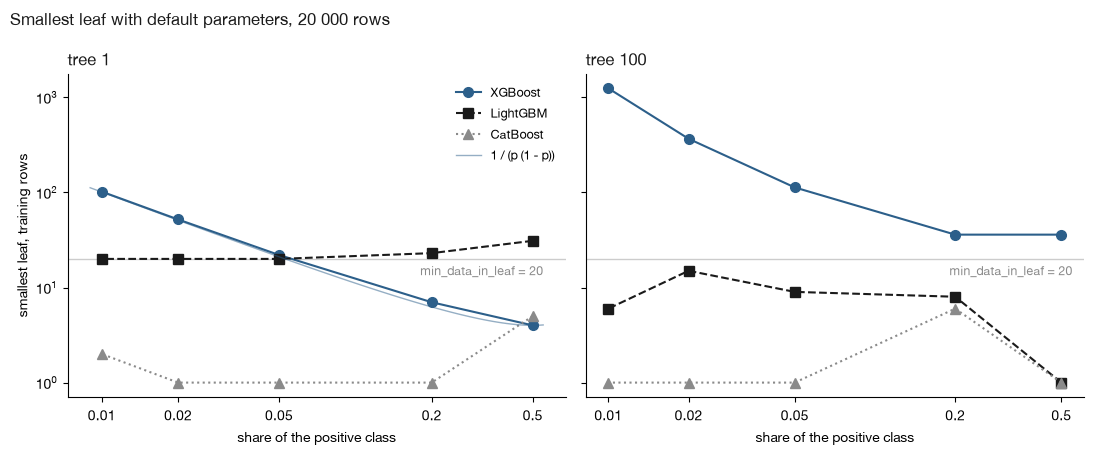

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
STYLE = {"XGBoost": (BLUE, "o", "-"), "LightGBM": (INK, "s", "--"), "CatBoost": (GREY, "^", ":")}
for ax, tree in zip(axes, (1, 100)):
    for name, (color, marker, ls) in STYLE.items():
        g = LEAF[LEAF.library == name]
        ax.plot(g.share, g[f"min rows, tree {tree}"], color=color, marker=marker, ls=ls, lw=1.5, ms=7, label=name)
    if tree == 1:
        grid = np.geomspace(0.009, 0.55, 100)
        ax.plot(grid, 1 / (grid * (1 - grid)), color=BLUE, lw=1, alpha=0.5, label="1 / (p (1 - p))")
    ax.axhline(20, color="#cccccc", lw=1, zorder=0)
    ax.text(0.55, 18, "min_data_in_leaf = 20", color=GREY, fontsize=9, ha="right", va="top")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xticks(SHARES, [f"{s:g}" for s in SHARES])
    ax.minorticks_off()
    ax.set_xlabel("share of the positive class")
    ax.set_title(f"tree {tree}", loc="left", color=INK)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("smallest leaf, training rows")
axes[0].legend(frameon=False, fontsize=9)
fig.suptitle("Smallest leaf with default parameters, 20 000 rows", x=0.01, ha="left", color=INK)
fig.tight_layout()
fig.savefig("gbdt_defaults_min_leaf.png", dpi=150, facecolor="white")
plt.show()

## 5. Regularization

The values from the table in section 0.

In [13]:
print(DEFAULTS.loc[["L2", "L1", "min split gain", "min leaf", "split noise"]].to_string())

                           XGBoost                                            LightGBM            CatBoost
L2                               1                                                   0                   3
L1                               0                                                   0                none
min split gain                   0                                                   0                none
min leaf        min_child_weight=1  min_data_in_leaf=20, min_sum_hessian_in_leaf=0.001  min_data_in_leaf=1
split noise                   none                                                none   random_strength=1


XGBoost has `lambda=1`, `alpha=0` and `gamma=0`; LightGBM `reg_lambda=0` and `reg_alpha=0`; CatBoost
`l2_leaf_reg=3` and `random_strength=1`. The
[CatBoost docs](https://catboost.ai/docs/en/references/training-parameters/common#random_strength)
describe `random_strength`: "A normally distributed random variable is added to the score of the
feature. It has a zero mean and a variance that decreases during the training. The value of this
parameter is the multiplier of the variance." The same page lists it as CPU only.

## 6. Randomness by default

First the sampling CatBoost picks on CPU for four losses, then five seeds of each library's defaults
on one `phoneme` split.

In [14]:
group = np.repeat(np.arange(200), 10)
picked = {}
for loss, model, y_ in (("Logloss", CatBoostClassifier, y_small), ("RMSE", CatBoostRegressor, y_small.astype(float)),
                        ("MultiClass", CatBoostClassifier, np.arange(2000) % 3)):
    picked[loss] = first_tree_params(model(loss_function=loss, **QUIET), X_small, y_)
for loss in ("YetiRank", "YetiRankPairwise"):
    picked[loss] = first_tree_params(CatBoost(dict(loss_function=loss, **QUIET)), Pool(X_small, y_small, group_id=group))
picked["Logloss, 90 rows"] = first_tree_params(CatBoostClassifier(**QUIET), X_small[:90], y_small[:90])
print(pd.DataFrame({k: {"bootstrap_type": p["bootstrap_type"], "subsample": p.get("subsample"),
                        "bagging_temperature": p.get("bagging_temperature"), "boosting_type": p["boosting_type"]}
                    for k, p in picked.items()}).T.to_string())

                 bootstrap_type subsample bagging_temperature boosting_type
Logloss                     MVS       0.8                None         Plain
RMSE                        MVS       0.8                None         Plain
MultiClass             Bayesian      None                   1         Plain
YetiRank                    MVS       0.8                None         Plain
YetiRankPairwise      Bernoulli       0.5                None         Plain
Logloss, 90 rows            MVS         1                None         Plain


On CPU `Logloss`, `RMSE` and `YetiRank` get MVS with `subsample=0.8`, `MultiClass` gets the Bayesian
bootstrap and `YetiRankPairwise` gets Bernoulli with 0.5. Below 100 rows the subsample is 1. Every one
of these fits used `Plain` boosting, so Bayesian is not tied to `Ordered` boosting. The
[`bootstrap_type` docs](https://catboost.ai/docs/en/references/training-parameters/common#bootstrap_type),
section Default value:

> When the objective parameter is QueryCrossEntropy, YetiRankPairwise, PairLogitPairwise and the
> bagging_temperature parameter is not set: Bernoulli with the subsample parameter set to 0.5.
> Neither MultiClass nor MultiClassOneVsAll, task_type = CPU and sampling_unit = Object: MVS with the
> subsample parameter set to 0.8. Otherwise: Bayesian.

The rule names the loss, the processing unit and the sampling unit, not the boosting scheme. The
documentation does not link Bayesian bootstrap to `Ordered` boosting. One sentence in it is out of
date: `bagging_temperature` "Defines the settings of the Bayesian bootstrap. It is used by default in
classification and regression modes", while on CPU binary classification and regression get MVS.

In [15]:
X_tr, X_te, y_tr, y_te = train_test_split(X_ph, y_ph, test_size=0.25, stratify=y_ph, random_state=SEED)


VARIANTS = {
    "XGBoost": (DEFAULT["XGBoost"], {}),
    "LightGBM": (DEFAULT["LightGBM"], {}),
    "CatBoost": (DEFAULT["CatBoost"], {}),
    "CatBoost, bootstrap_type=No": (DEFAULT["CatBoost"], {"bootstrap_type": "No"}),
    "CatBoost, random_strength=0": (DEFAULT["CatBoost"], {"random_strength": 0}),
    "CatBoost, both": (DEFAULT["CatBoost"], {"bootstrap_type": "No", "random_strength": 0}),
    "XGBoost, subsample 0.8, colsample_bytree 0.8": (DEFAULT["XGBoost"], {"subsample": 0.8, "colsample_bytree": 0.8}),
    "LightGBM, subsample 0.8 every tree, colsample_bytree 0.8": (
        DEFAULT["LightGBM"], {"subsample": 0.8, "subsample_freq": 1, "colsample_bytree": 0.8}),
}
# Test probabilities per variant and seed; section 8 reuses CatBoost's, since Plain is its CPU default.
PROBS = {name: np.array([make(random_state=s, **params).fit(X_tr, y_tr).predict_proba(X_te)[:, 1] for s in SEEDS])
         for name, (make, params) in VARIANTS.items()}
SPREAD = pd.DataFrame({name: {"largest p difference between seeds": np.ptp(p, axis=0).max(),
                              "SD of log loss": np.std([log_loss(y_te, q) for q in p], ddof=1)}
                       for name, p in PROBS.items()}).T
print(f"phoneme, {len(y_tr)} training and {len(y_te)} test rows, {len(SEEDS)} seeds")
print(SPREAD.round(4).to_string())

phoneme, 4053 training and 1351 test rows, 5 seeds
                                                          largest p difference between seeds  SD of log loss
XGBoost                                                                               0.0000          0.0000
LightGBM                                                                              0.0000          0.0000
CatBoost                                                                              0.1982          0.0005
CatBoost, bootstrap_type=No                                                           0.2173          0.0015
CatBoost, random_strength=0                                                           0.1849          0.0009
CatBoost, both                                                                        0.0000          0.0000
XGBoost, subsample 0.8, colsample_bytree 0.8                                          0.7210          0.0030
LightGBM, subsample 0.8 every tree, colsample_bytree 0.8                     

With their defaults XGBoost and LightGBM give the same predictions for every seed: nothing in them is
random. CatBoost's seeds move single probabilities by up to about 0.2 while the test log loss moves
by a few ten-thousandths. Turning off either source alone, the bootstrap or the split noise, leaves
the spread; only both together remove it. XGBoost and LightGBM with row and column sampling spread
more than CatBoost does at its defaults.

## 7. Quantization

In [16]:
print(DEFAULTS.loc[["bins", "split finding"]].to_string())

                                                         XGBoost   LightGBM              CatBoost
bins                                                         256        255                   254
split finding  tree_method=auto, updater=grow_quantile_histmaker  histogram  GreedyLogSum borders


All three bucket features before searching splits, with a similar number of bins: XGBoost `max_bin=256`
("Maximum number of discrete bins to bucket continuous features",
[parameter docs](https://github.com/dmlc/xgboost/blob/v3.4.1/doc/parameter.rst)), LightGBM
`max_bin=255` ("max number of bins that feature values will be bucketed in",
[parameter docs](https://lightgbm.readthedocs.io/en/v4.7.0/Parameters.html#max_bin)) and CatBoost
`border_count=254` on CPU ("The number of splits for numerical features",
[quantization docs](https://catboost.ai/docs/en/references/training-parameters/quantization#border_count);
128 on GPU).

## 8. Ordered and Plain boosting

Which scheme CatBoost picks on CPU around 50 000 rows, with and without a categorical feature.

In [17]:
X_big, y_big = make_classification(200_000, 10, n_informative=5, n_redundant=0, random_state=SEED)
with_cat = pd.DataFrame(X_big).assign(cat=np.random.default_rng(SEED).integers(0, 20, len(X_big)).astype(str))
scheme = {n: {"numeric": first_tree_params(CatBoostClassifier(**QUIET), X_big[:n], y_big[:n])["boosting_type"],
              "with a categorical column": first_tree_params(CatBoostClassifier(cat_features=["cat"], **QUIET),
                                                             with_cat.iloc[:n], y_big[:n])["boosting_type"]}
          for n in (1_000, 20_000, 49_999, 50_000, 200_000)}
print(pd.DataFrame(scheme).T.rename_axis("rows").to_string())

       numeric with a categorical column
rows                                    
1000     Plain                     Plain
20000    Plain                     Plain
49999    Plain                     Plain
50000    Plain                     Plain
200000   Plain                     Plain


On CPU CatBoost picks `Plain` at every size. The 50 000 threshold is a GPU rule. The
[`boosting_type` docs](https://catboost.ai/docs/en/references/training-parameters/common#boosting_type),
Default value: "CPU: Plain. GPU: Any number of objects, MultiClass or MultiClassOneVsAll mode: Plain.
More than 50 thousand objects, any mode: Plain. Less than or equal to 50 thousand objects, any mode
but MultiClass or MultiClassOneVsAll: Ordered." So on GPU exactly 50 000 rows still get `Ordered`.
The [FAQ](https://catboost.ai/docs/en/concepts/faq#overcome-out-of-memory), under "How to overcome
the Out of memory error when training on GPU?", puts the boundary the other way: "It is set to
Ordered by default for datasets with less then 50 thousand objects." The GPU cell at the end of this
section reads what the GPU build does.

What `Ordered` costs on CPU: 500 trees, the scheme set explicitly, the median of three runs.

In [18]:
def seconds(n, scheme_name):
    """Median wall time of three 500-tree fits on the first n rows."""
    runs = []
    for _ in range(3):
        start_time = time.perf_counter()
        CatBoostClassifier(iterations=500, boosting_type=scheme_name, **QUIET).fit(X_big[:n], y_big[:n])
        runs.append(time.perf_counter() - start_time)
    return np.median(runs)


TIMING = pd.DataFrame({n: {s: seconds(n, s) for s in ("Ordered", "Plain")} for n in (5_000, 20_000, 50_000)}).T.rename_axis("rows")
TIMING["Ordered / Plain"] = TIMING.Ordered / TIMING.Plain
print(f"seconds, {THREADS} CPU threads")
print(TIMING.round(2).to_string())

ordered = [log_loss(y_te, CatBoostClassifier(random_seed=s, boosting_type="Ordered", **QUIET).fit(X_tr, y_tr).predict_proba(X_te))
           for s in SEEDS]
plain = [log_loss(y_te, p) for p in PROBS["CatBoost"]]
print("\nphoneme test log loss, Ordered minus Plain, per seed:", (np.array(ordered) - plain).round(4))

seconds, 14 CPU threads
       Ordered  Plain  Ordered / Plain
rows                                  
5000      1.27   0.51             2.48
20000     2.74   1.11             2.46
50000     3.74   2.33             1.61



phoneme test log loss, Ordered minus Plain, per seed: [0.026  0.0234 0.0235 0.0282 0.014 ]


`Ordered` is slower than `Plain` at every size. The ratio depends on the machine, the threads and the
data, and it moved between runs on the same laptop, so the table is an example, not a constant. Prokhorenkova et al. (NeurIPS 2018) report
1.1 s against 1.9 s per tree on Epsilon, a factor of about 1.7; that figure belongs to their data and
hardware. On `phoneme` `Ordered` has a higher test log loss than `Plain` on all five seeds.

The next cell reads the GPU defaults at the 50 000 boundary. Without a GPU it prints `skipped`.

In [19]:
if get_gpu_device_count() == 0:
    print("GPU: skipped, no CUDA device visible to CatBoost")
else:
    X_gpu, y_gpu = make_classification(60_000, 10, n_informative=5, n_redundant=0, n_classes=3, random_state=SEED)
    gpu = {}
    for loss, y_ in (("Logloss", (y_gpu == 0).astype(int)), ("MultiClass", y_gpu)):
        for n in (30_000, 49_999, 50_000, 50_001, 60_000):
            # Custom callbacks are CPU only, so the GPU fit builds one tree.
            p = CatBoostClassifier(loss_function=loss, task_type="GPU", iterations=1, **QUIET).fit(X_gpu[:n], y_[:n]).get_all_params()
            gpu[(loss, n)] = {"boosting_type": p["boosting_type"], "border_count": p["border_count"]}
    print(pd.DataFrame(gpu).T.to_string())

GPU: skipped, no CUDA device visible to CatBoost


## 9. Categorical columns

The `adult` frame has 8 columns of dtype `category`, three of them with missing values. It goes to
each classifier as is, with no arguments.

In [20]:
def try_fit(label, model, X):
    try:
        model.fit(X, y_ad)
        print(f"{label}: trained")
    except CatBoostError as error:
        print(f"{label}: CatBoostError: {error}")


for name, make in DEFAULT.items():
    try_fit(name, make(), X_ad)
try_fit("CatBoost, cat_features named", DEFAULT["CatBoost"](cat_features=CATS), X_ad)

X_ad_cb = X_ad.copy()
for c in CATS:
    X_ad_cb[c] = X_ad_cb[c].cat.add_categories("missing").fillna("missing")
cb_cat = first_tree_params(CatBoostClassifier(cat_features=CATS, **QUIET), X_ad_cb, y_ad)
print("\none-hot thresholds: XGBoost max_cat_to_onehot",
      xgb_config(fitted["XGBoost"])["gradient_booster"]["tree_train_param"]["max_cat_to_onehot"],
      "| LightGBM max_cat_to_onehot", lgb_model_params(fitted["LightGBM"])["max_cat_to_onehot"],
      "| CatBoost one_hot_max_size", cb_cat["one_hot_max_size"])

XGBoost: trained


LightGBM: trained
CatBoost: CatBoostError: features data: pandas.DataFrame column 'workclass' has dtype 'category' but is not in  cat_features list
CatBoost, cat_features named: CatBoostError: Invalid type for cat_feature[object_idx=4,feature_idx=1]=NaN : cat_features must be integer or string, real number values and NaN values should be converted to string.

one-hot thresholds: XGBoost max_cat_to_onehot 4 | LightGBM max_cat_to_onehot 4 | CatBoost one_hot_max_size 2


XGBoost and LightGBM train on the frame as it is. XGBoost's sklearn class has had
`enable_categorical=True` by default since 3.3.0
([release notes](https://github.com/dmlc/xgboost/blob/v3.4.1/doc/changes/v3.3.0.rst): "Enable
categorical feature support by default while keeping `enable_categorical` available for users who need
to disable it"); its
[categorical tutorial](https://github.com/dmlc/xgboost/blob/v3.4.1/doc/tutorials/categorical.rst)
still tells the reader to set it. LightGBM's sklearn `fit` takes `categorical_feature="auto"`
([API docs](https://lightgbm.readthedocs.io/en/v4.7.0/pythonapi/lightgbm.LGBMClassifier.html)): "If
'auto' and data is pandas DataFrame, pandas unordered categorical columns are used."

CatBoost refuses: a `category` column must be named in `cat_features`, and once it is, a missing value
in it is an error too, so the frame needs a filled-in category before CatBoost accepts it. Whatever
CatBoost does well with categorical features, it does not do it with no arguments.

The one-hot thresholds are all small. XGBoost's `max_cat_to_onehot=4`
([parameter docs](https://github.com/dmlc/xgboost/blob/v3.4.1/doc/parameter.rst)): "When number of categories is
lesser than the threshold then one-hot encoding is chosen". LightGBM's `max_cat_to_onehot=4`
([parameter docs](https://lightgbm.readthedocs.io/en/v4.7.0/Parameters.html#max_cat_to_onehot)): "when
number of categories of one feature smaller than or equal to `max_cat_to_onehot`, one-vs-other split
algorithm will be used". CatBoost's `one_hot_max_size=2` on CPU
([docs](https://catboost.ai/docs/en/references/training-parameters/common#one_hot_max_size)): "Use one-hot encoding for all
categorical features with a number of different values less than or equal to the given parameter
value".

## 10. An `eval_set` without early stopping

`phoneme` split into 60% train, 20% valid and 20% test, five split seeds. Each library is fitted with
and without `eval_set=valid` and no early stopping.

In [21]:
def three_way(X, y, seed):
    """60% train, 20% valid, 20% test, stratified."""
    X_a, X_rest, y_a, y_rest = train_test_split(X, y, test_size=0.4, stratify=y, random_state=seed)
    X_v, X_t, y_v, y_t = train_test_split(X_rest, y_rest, test_size=0.5, stratify=y_rest, random_state=seed)
    return X_a, X_v, X_t, y_a, y_v, y_t


rows, SEED0 = [], {}
for seed in SEEDS:
    X_a, X_v, X_t, y_a, y_v, y_t = three_way(X_ph, y_ph, seed)
    eval_kw = {"XGBoost": {"eval_set": [(X_v, y_v)], "verbose": False},
               "LightGBM": {"eval_X": X_v, "eval_y": y_v}, "CatBoost": {"eval_set": (X_v, y_v)}}
    for name, make in DEFAULT.items():
        plain, with_eval = make().fit(X_a, y_a), make().fit(X_a, y_a, **eval_kw[name])
        if seed == SEED:
            SEED0[name] = plain, with_eval  # reused by the learning curves below
        row = {"seed": seed, "library": name, "trees": n_trees(with_eval),
               "same predictions as without eval_set": np.array_equal(plain.predict_proba(X_t), with_eval.predict_proba(X_t)),
               "log loss, eval_set rows": log_loss(y_v, with_eval.predict_proba(X_v)),
               "log loss, other rows": log_loss(y_t, with_eval.predict_proba(X_t))}
        if name == "CatBoost":
            # The same model selected on the test rows instead: the gap is what selecting on a set buys on that set.
            on_test = make().fit(X_a, y_a, eval_set=(X_t, y_t))
            row["selection gain on its own set"] = row["log loss, other rows"] - log_loss(y_t, on_test.predict_proba(X_t))
            row["learning rate"] = with_eval.get_all_params()["learning_rate"]
            row["learning rate without eval_set"] = plain.get_all_params()["learning_rate"]
        rows.append(row)
EVAL = pd.DataFrame(rows)
EVAL["other minus eval_set rows"] = EVAL["log loss, other rows"] - EVAL["log loss, eval_set rows"]
print(EVAL.drop(columns=["log loss, eval_set rows", "log loss, other rows"]).round(4).to_string(index=False))

 seed  library  trees  same predictions as without eval_set  selection gain on its own set  learning rate  learning rate without eval_set  other minus eval_set rows
    0  XGBoost    100                                  True                            NaN            NaN                             NaN                     0.0781
    0 LightGBM    100                                  True                            NaN            NaN                             NaN                     0.0531
    0 CatBoost    998                                 False                         0.0106         0.0424                           0.017                     0.0814
    1  XGBoost    100                                  True                            NaN            NaN                             NaN                    -0.0146
    1 LightGBM    100                                  True                            NaN            NaN                             NaN                    -0.0134
    1 CatB

XGBoost and LightGBM keep all 100 trees and predict exactly what they predict without the `eval_set`:
it only adds a printed curve (XGBoost prints it every round unless `fit` gets `verbose=False`).
LightGBM 4.7 deprecates `eval_set` in its sklearn `fit` in favour of `eval_X` and `eval_y`, which the
cell uses. CatBoost
turns on `use_best_model`, keeps the trees up to the best iteration on the `eval_set`, and trains at a
different learning rate from the start (section 2), so its predictions change.

The difference between the log loss on the other rows and on the `eval_set` rows mixes two things:
which rows are easier, which differs from seed to seed for all three libraries, and the selection,
which only CatBoost does. The selection part alone is the last CatBoost column: the same fit,
truncated at the best iteration on the test rows instead of the valid rows, scored on the test rows.
It is never negative, and here it is small because the curve is flat near its minimum.

## 11. Overfitting on small data

A common claim is that leaf-wise growth overfits aggressively below about 10 000 rows. Here the
defaults of all three are fitted on 500, 2000 and 10 000 rows of `adult` (the categories as integer
codes, so all three see the same numeric matrix), five draws each, and scored on the same 10 000
held-out rows.

In [22]:
X_codes = X_ad.apply(lambda c: c.cat.codes if c.dtype == "category" else c).to_numpy(float)
X_pool, X_hold, y_pool, y_hold = train_test_split(X_codes, y_ad, test_size=10_000, stratify=y_ad, random_state=SEED)
rows = []
for n in (500, 2_000, 10_000):
    for seed in SEEDS:
        idx = np.random.default_rng(seed).choice(len(y_pool), n, replace=False)
        for name, make in DEFAULT.items():
            model = make().fit(X_pool[idx], y_pool[idx])
            train_ll = log_loss(y_pool[idx], model.predict_proba(X_pool[idx]))
            test_ll = log_loss(y_hold, model.predict_proba(X_hold))
            rows.append({"rows": n, "library": name, "test log loss": test_ll, "test minus train": test_ll - train_ll})
SMALL = pd.DataFrame(rows).groupby(["rows", "library"], sort=False).mean()
print(SMALL.unstack("library").round(3).to_string())

        test log loss                   test minus train                  
library       XGBoost LightGBM CatBoost          XGBoost LightGBM CatBoost
rows                                                                      
500             0.486    0.439    0.342            0.458    0.392    0.199
2000            0.381    0.354    0.316            0.306    0.252    0.132
10000           0.302    0.290    0.288            0.139    0.083    0.073


All three overfit on 500 rows with their defaults, and the gap shrinks with more rows. LightGBM's gap
is smaller than XGBoost's at every size, and its test log loss is lower: leaf-wise growth with 31
leaves and at least 20 rows per leaf overfits less here than depth-wise growth with `max_depth=6`,
`min_child_weight=1` and a learning rate of 0.3. CatBoost has the smallest gap and the lowest test log
loss; on 500 rows its automatic learning rate is about 0.008. The numbers support "defaults overfit on
small data", not "leaf-wise overfits more". LightGBM's
[Features page](https://lightgbm.readthedocs.io/en/v4.7.0/Features.html#leaf-wise-best-first-tree-growth)
says "Leaf-wise may cause over-fitting when #data is small" and gives no size.

## Test loss against the number of trees

`phoneme`, 60% train, 20% valid and 20% test with a fixed seed. XGBoost and LightGBM are fitted with
1000 trees at their default learning rates, and the curve for the first `t` trees comes from
`iteration_range` and `num_iteration`. That model's first 100 trees must equal the default model with
100 trees; the cell checks it. CatBoost's default already has 1000 trees. Its `use_best_model` point is
read from a second fit with `eval_set=valid`, which trains at another learning rate, so it is drawn as
its own curve. The default models are the seed-0 fits of section 10, on the same split.

In [23]:
X_a, X_v, X_t, y_a, y_v, y_t = three_way(X_ph, y_ph, SEED)
xgb_1000 = xgb.XGBClassifier(n_estimators=1000).fit(X_a, y_a)
lgb_1000 = DEFAULT["LightGBM"](n_estimators=1000).fit(X_a, y_a)
cat_default, cat_eval = SEED0["CatBoost"]
print("first 100 of 1000 trees equal the 100-tree default:",
      "XGBoost", np.allclose(xgb_1000.predict_proba(X_t, iteration_range=(0, 100)), SEED0["XGBoost"][0].predict_proba(X_t)),
      "| LightGBM", np.allclose(lgb_1000.predict_proba(X_t, num_iteration=100), SEED0["LightGBM"][0].predict_proba(X_t)))


def staged(model, steps):
    """Test log loss of a CatBoost model's first t trees, for each t in steps."""
    return pd.Series([log_loss(y_t, p) for t, p in enumerate(model.staged_predict_proba(X_t), 1) if t in steps],
                     index=[t for t in steps if t <= model.tree_count_])


STEPS = np.unique(np.r_[np.geomspace(1, 1000, 60).round().astype(int), 100])
CURVES = {
    "XGBoost": pd.Series([log_loss(y_t, xgb_1000.predict_proba(X_t, iteration_range=(0, t))) for t in STEPS], index=STEPS),
    "LightGBM": pd.Series([log_loss(y_t, lgb_1000.predict_proba(X_t, num_iteration=t)) for t in STEPS], index=STEPS),
    "CatBoost": staged(cat_default, STEPS),
    "CatBoost with eval_set": staged(cat_eval, STEPS),
}
STOPS = DEFAULTS.loc["trees"].to_dict() | {"CatBoost with eval_set": cat_eval.tree_count_}
curve = pd.DataFrame(CURVES)
summary = pd.DataFrame({name: {"default trees": STOPS[name], "test log loss there": log_loss(y_t, model.predict_proba(X_t)),
                               "best test log loss": curve[name].min(), "at trees": curve[name].idxmin(),
                               "test log loss at 1000": curve[name].get(1000)}
                        for name, model in (("XGBoost", SEED0["XGBoost"][0]), ("LightGBM", SEED0["LightGBM"][0]),
                                            ("CatBoost", cat_default), ("CatBoost with eval_set", cat_eval))}).T
print(summary.round(4).to_string())
print("CatBoost learning rate, default and with eval_set:",
      round(cat_default.get_all_params()["learning_rate"], 4), round(cat_eval.get_all_params()["learning_rate"], 4))

first 100 of 1000 trees equal the 100-tree default: XGBoost True | LightGBM True


                        default trees  test log loss there  best test log loss  at trees  test log loss at 1000
XGBoost                         100.0               0.3611              0.3358      21.0                 0.5703
LightGBM                        100.0               0.3252              0.3177      48.0                 0.8336
CatBoost                       1000.0               0.3218              0.3218    1000.0                 0.3218
CatBoost with eval_set          998.0               0.3375              0.3268     392.0                    NaN
CatBoost learning rate, default and with eval_set: 0.017 0.0424


XGBoost reaches its lowest test loss within a few dozen trees, and its default 100 trees are already
past it. LightGBM's default 100 is close to its best, and both rise steeply if the tree count is raised
without early stopping. CatBoost, at its automatic rate for 1000 iterations, is still improving at
1000. With an `eval_set` CatBoost trains at more than twice the rate and keeps the trees up to the
best iteration on valid. The table gives the numbers.

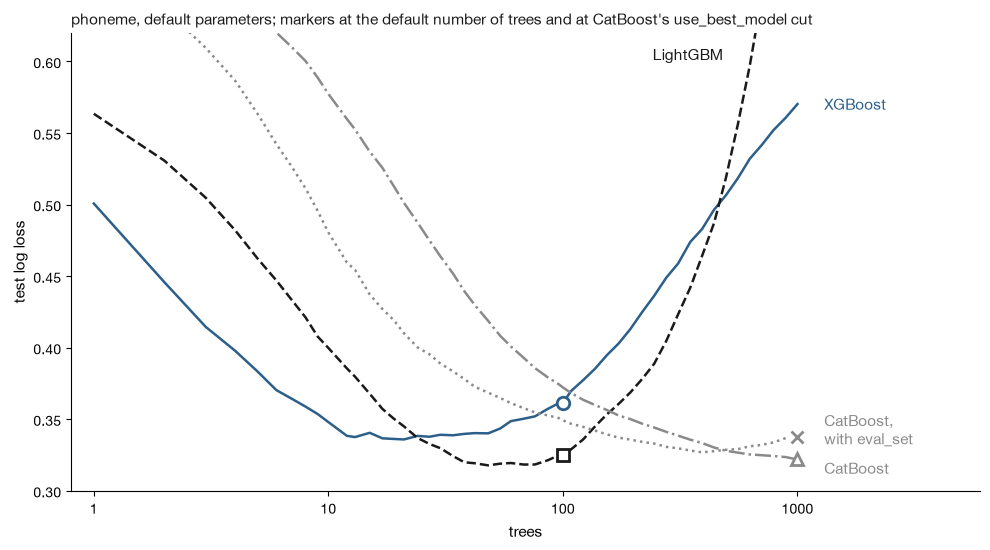

In [24]:
LINES = {"XGBoost": (BLUE, "-", "o", "XGBoost"), "LightGBM": (INK, "--", "s", "LightGBM"),
         "CatBoost": (GREY, "-.", "^", "CatBoost"), "CatBoost with eval_set": (GREY, ":", "x", "CatBoost,\nwith eval_set")}
Y_TOP = 0.62


def draw_curves(ax, fontsize, lw, ms, xmax, gap):
    """Curves with a marker where each model stops, labelled right of the 1000-tree end;
    LightGBM's curve leaves the top of the axis earlier, so its label sits there."""
    nudge = {"CatBoost": -gap / 2, "CatBoost with eval_set": gap / 2}
    for name, (color, ls, marker, label) in LINES.items():
        s = CURVES[name]
        ax.plot(s.index, s, color=color, ls=ls, lw=lw)
        ax.plot(*summary.loc[name, ["default trees", "test log loss there"]], marker=marker, color=color,
                ms=ms, mew=2, mfc="white", ls="")
        if name == "LightGBM":
            ax.text(480, Y_TOP - 0.015, label, color=color, fontsize=fontsize, ha="right", va="center")
        else:
            ax.text(1300, s.iloc[-1] + nudge.get(name, 0), label, color=color, fontsize=fontsize, va="center")
    ax.set_xscale("log")
    ax.set_xticks([1, 10, 100, 1000], ["1", "10", "100", "1000"])
    ax.minorticks_off()
    ax.set_xlim(0.8, xmax)
    ax.set_ylim(0.3, Y_TOP)
    ax.set_xlabel("trees", fontsize=fontsize)
    ax.set_ylabel("test log loss", fontsize=fontsize)
    ax.spines[["top", "right"]].set_visible(False)


fig, ax = plt.subplots(figsize=(10, 5.6))
draw_curves(ax, 11, 1.8, 9, 6000, 0.012)
ax.set_title("phoneme, default parameters; markers at the default number of trees and at CatBoost's use_best_model cut",
             loc="left", fontsize=11, color=INK)
fig.tight_layout()
fig.savefig("gbdt_defaults_curves.png", dpi=150, facecolor="white")
plt.show()

The same figure for a square post, 1200 by 1200 pixels, no text smaller than 36 pixels.

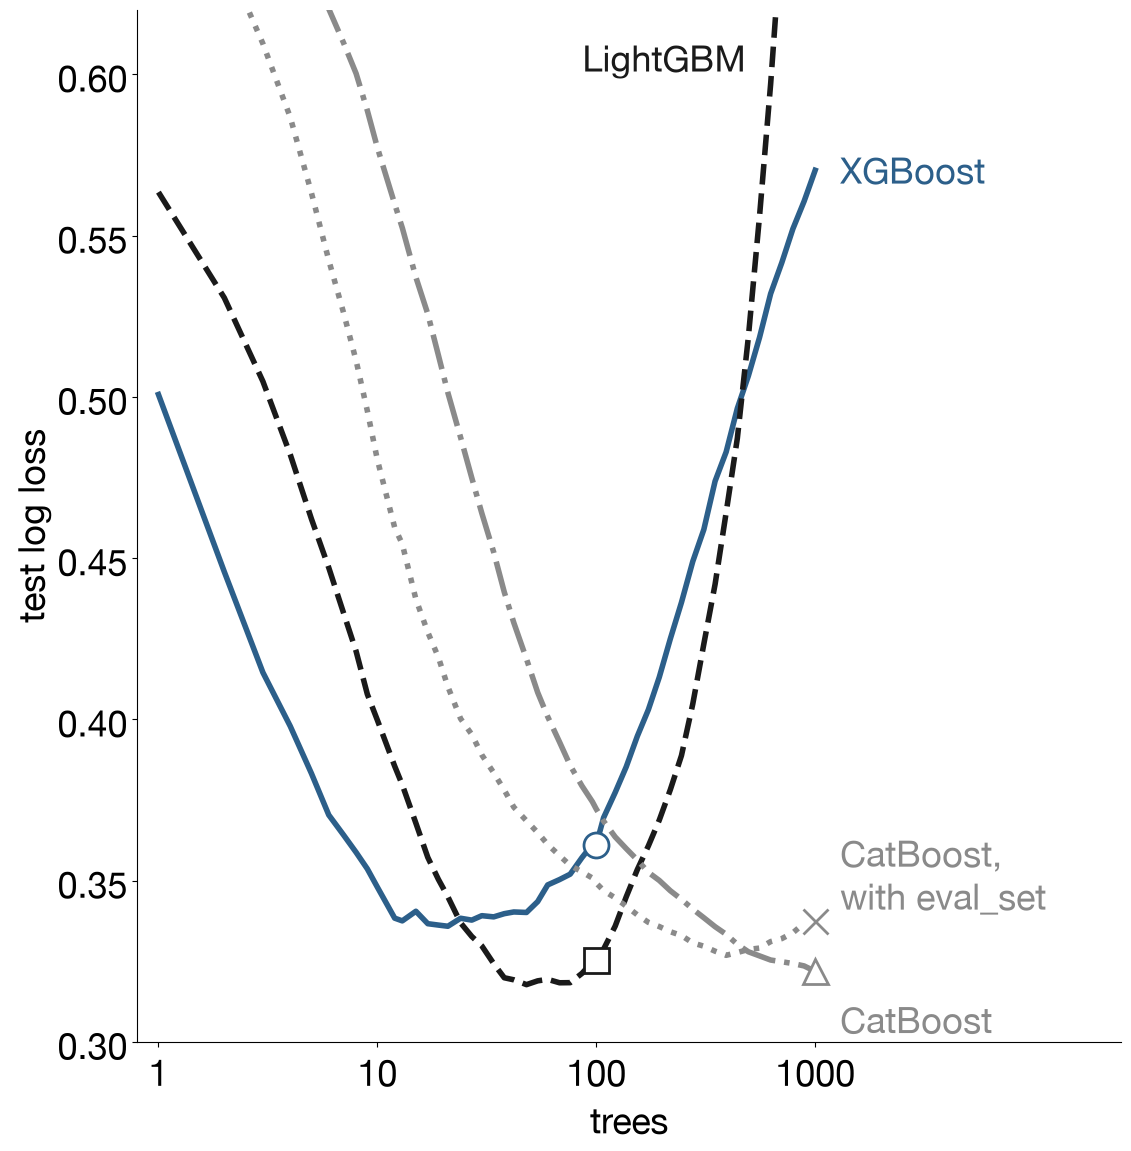

In [25]:
PX = 72 / 100  # points per pixel at 100 dpi
with plt.rc_context({"font.size": 36 * PX, "xtick.labelsize": 36 * PX, "ytick.labelsize": 36 * PX}):
    fig, ax = plt.subplots(figsize=(12, 12), dpi=100)
    draw_curves(ax, 36 * PX, 4, 18, 25_000, 0.03)
    fig.subplots_adjust(left=0.16, right=0.98, top=0.96, bottom=0.1)
    fig.savefig("gbdt_defaults_curves_linkedin.png", dpi=100, facecolor="white")
plt.show()

## Takeaway

- Read defaults from a fitted model, not from the estimator object. `XGBClassifier()` holds `None`,
  `CatBoostClassifier().get_params()` is empty, and `xgb.train` defaults to 10 rounds, not none.
- CatBoost's learning rate is a function of the rows, the iterations, the loss and the presence of an
  `eval_set`. Setting `l2_leaf_reg`, `leaf_estimation_iterations` or `leaf_estimation_method`, even to
  its default value, fixes it at 0.03. A run with an `eval_set` is not the default model.
- All three adapt something to the data: XGBoost and LightGBM start from the class prior, and
  XGBoost's minimum leaf in rows depends on the class share. CatBoost does not switch to `Ordered`
  on CPU at any size; the 50 000-row rule is for GPU.
- LightGBM's `min_data_in_leaf` and XGBoost's `min_child_weight` are not row counts on a binary task
  after the first tree.
- With defaults, XGBoost and LightGBM are deterministic; CatBoost is not, through MVS sampling and
  `random_strength` together.
- On small data all three overfit with their defaults, XGBoost the most; leaf-wise growth is not the
  worst of the three here.